# Probability distributions

## Saved data

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'FULL_RECORD_START_HERE.txt').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from tools.scientific_plot_style import BLUE, RED

DATA = ROOT/'notebooks/final/data07'
assert hashlib.sha256((DATA/'manifest.json').read_bytes()).hexdigest() == 'f1936e6310310c024823a07801ddb294e44de2b1c4562f004a24a84f55ab927b'
manifest = json.loads((DATA/'manifest.json').read_text())
for filename, expected in manifest['files'].items():
    assert hashlib.sha256((ROOT/filename).read_bytes()).hexdigest() == expected, filename
source = json.loads((ROOT/manifest['source_config']).read_text())
for filename, expected in source['files'].items():
    assert hashlib.sha256((ROOT/filename).read_bytes()).hexdigest() == expected, filename

observations = pd.read_parquet(DATA/'observations.parquet')
curves = pd.read_parquet(DATA/'curves.parquet')
result_table = pd.read_parquet(DATA/'results.parquet')
samples = {name: group.value.to_numpy(dtype=int if name in
           ('Monthly AR-event count', 'AR event duration') else float)
           for name, group in observations.groupby('variable', sort=False)}


## Distributions

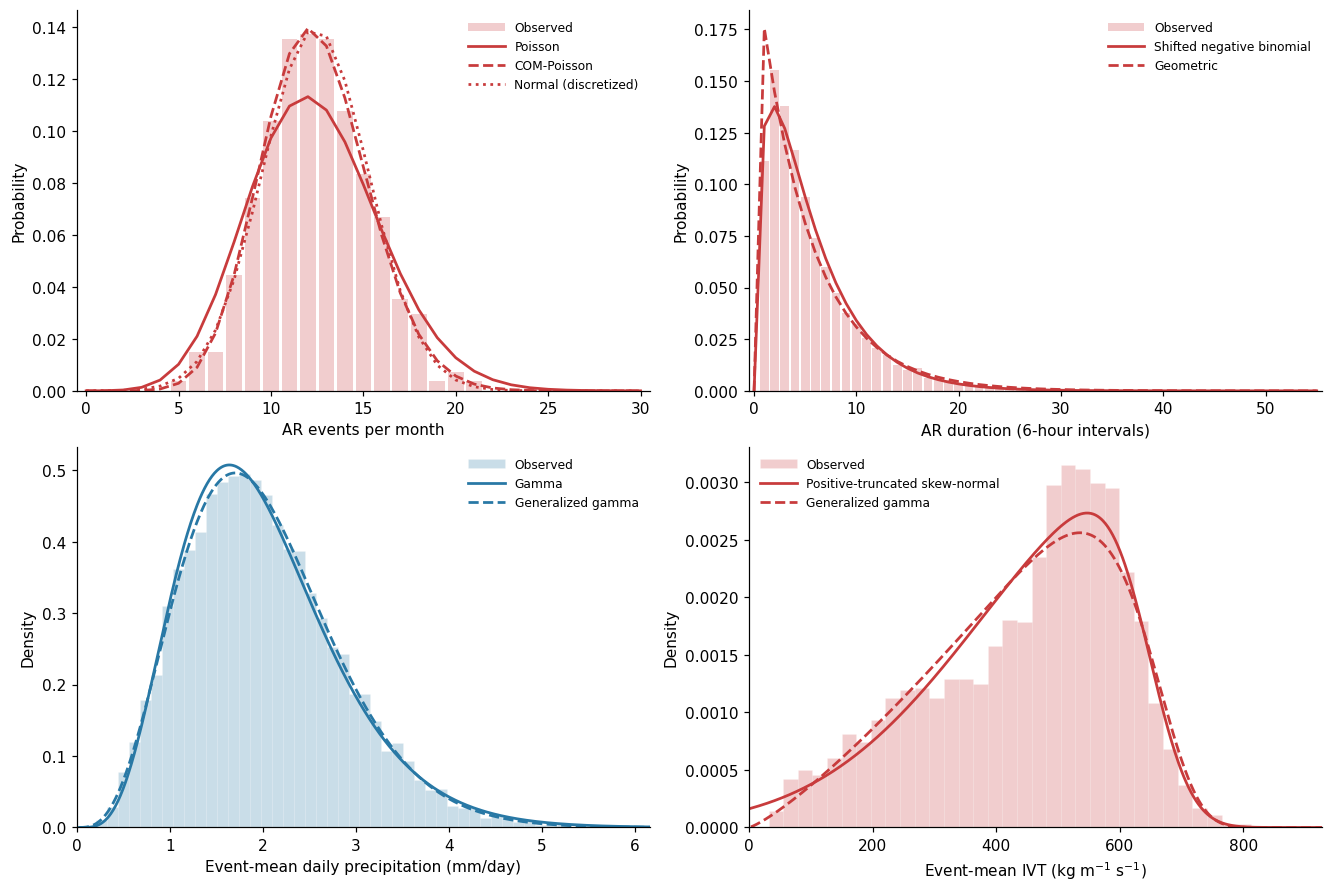

In [2]:
panels = [
    ('Monthly AR-event count', RED, 'AR events per month'),
    ('AR event duration', RED, 'AR duration (6-hour intervals)'),
    ('Event-mean daily precipitation', BLUE, 'Event-mean daily precipitation (mm/day)'),
    ('Event-mean IVT', RED, r'Event-mean IVT (kg m$^{-1}$ s$^{-1}$)'),
]
with plt.rc_context({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'legend.frameon': False, 'figure.dpi': 110}):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout='constrained')
    for i, (ax, (variable, color, xlabel)) in enumerate(zip(axes.flat, panels)):
        x = samples[variable]
        models = result_table.loc[result_table.Variable.eq(variable), 'Candidate']
        c = curves[curves.variable.eq(variable)]
        if i < 2:
            grid = np.sort(c.x.unique()).astype(int)
            ax.bar(grid, np.bincount(x, minlength=len(grid)) / len(x),
                   color=color, alpha=.25, width=.85, label='Observed')
        else:
            ax.hist(x, bins='fd', density=True, color=color, alpha=.25,
                    edgecolor='white', linewidth=.4, label='Observed')
        for model, linestyle in zip(models, ['-', '--', ':']):
            curve = c[c.model.eq(model)]
            ax.plot(curve.x, curve.fitted, color=color, linestyle=linestyle,
                    linewidth=1.8, label=model)
        ax.set(xlabel=xlabel, ylabel='Probability' if i < 2 else 'Density',
               xlim=(-.5 if i < 2 else 0, c.x.max() + (.5 if i < 2 else 0)),
               ylim=(0, None))
        handles, labels = ax.get_legend_handles_labels()
        order = sorted(range(len(labels)), key=lambda j: labels[j] != 'Observed')
        ax.legend([handles[j] for j in order], [labels[j] for j in order],
                  loc='upper left' if i == 3 else 'upper right',
                  fontsize=8, handlelength=3)
    display(fig)
    plt.close(fig)

## Results

In [3]:
display(result_table.round({'AIC': 2, 'BIC': 2, 'GOF p': 3}))

,Variable,Candidate,AIC,BIC,GOF p,Decision
0,Monthly AR-event count,Poisson,2703.38,2707.68,0.002,Rejected
1,Monthly AR-event count,COM-Poisson,2661.96,2670.55,0.631,Selected
2,Monthly AR-event count,Normal (discretized),2664.49,2673.07,0.676,Not rejected; higher AIC
3,AR event duration,Shifted negative binomial,35257.98,35271.60,0.001,Best relative fit; rejected
4,AR event duration,Geometric,35463.28,35470.09,0.001,Rejected
5,Event-mean daily precipitation,Gamma,16040.08,16053.70,0.004,Rejected
6,Event-mean daily precipitation,Generalized gamma,16013.81,16034.24,0.681,Selected
7,Event-mean IVT,Positive-truncated skew-normal,85660.25,85680.68,0.001,Best relative fit; rejected
8,Event-mean IVT,Generalized gamma,85695.84,85716.27,0.001,Rejected
